In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import pandas as pd
import numpy as np

# Make the results reproducible
np.random.seed(42)

# Create 180 days of historical data
dates = pd.date_range(
    start="2026-01-01",
    periods=180,
    freq="D"
)

# Create basic cash demand
base_demand = np.random.normal(
    loc=800000,
    scale=120000,
    size=180
)

# Day of the week effect
day_of_week = dates.dayofweek

# Increase demand on Fridays
friday_effect = np.where(day_of_week == 4, 100000, 0)

# Increase demand around salary days
salary_day = dates.day.isin([1, 2, 3, 28, 29, 30, 31])
salary_effect = np.where(salary_day, 180000, 0)

# Simulate festival weeks
festival_dates = (
    ((dates >= "2026-03-10") & (dates <= "2026-03-16")) |
    ((dates >= "2026-05-01") & (dates <= "2026-05-07")) |
    ((dates >= "2026-10-20") & (dates <= "2026-10-27"))
)

festival_effect = np.where(festival_dates, 250000, 0)

# Total cash demand
cash_demand = (
    base_demand
    + friday_effect
    + salary_effect
    + festival_effect
)

# Avoid negative values
cash_demand = np.maximum(cash_demand, 200000)

# ATM withdrawals
atm_cash = cash_demand * np.random.uniform(
    0.25, 0.40, 180
)

# Teller cash
teller_cash = cash_demand - atm_cash

# Deposits
deposits = np.random.normal(
    loc=600000,
    scale=100000,
    size=180
)

deposits = np.maximum(deposits, 100000)

# Create DataFrame
df = pd.DataFrame({
    "Date": dates,
    "Cash_Demand": cash_demand.round(0),
    "ATM_Cash": atm_cash.round(0),
    "Teller_Cash": teller_cash.round(0),
    "Deposits": deposits.round(0),
    "Salary_Day": salary_day,
    "Festival_Week": festival_dates
})

# Display first 10 rows
df.head(10)

,Date,Cash_Demand,ATM_Cash,Teller_Cash,Deposits,Salary_Day,Festival_Week
0,2026-01-01,1039606.0,290348.0,749258.0,518178.0,True,False
1,2026-01-02,1063408.0,381091.0,682317.0,809239.0,True,False
2,2026-01-03,1057723.0,308978.0,748745.0,499398.0,True,False
3,2026-01-04,982764.0,249275.0,733488.0,478581.0,False,False
4,2026-01-05,771902.0,267712.0,504190.0,715811.0,False,False
5,2026-01-06,771904.0,213483.0,558421.0,679166.0,False,False
6,2026-01-07,989506.0,386965.0,602541.0,662412.0,False,False
7,2026-01-08,892092.0,350672.0,541420.0,662835.0,False,False
8,2026-01-09,843663.0,326691.0,516972.0,598775.0,False,False
9,2026-01-10,865107.0,264311.0,600796.0,510275.0,False,False


In [8]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (180, 7)

Column names:
['Date', 'Cash_Demand', 'ATM_Cash', 'Teller_Cash', 'Deposits', 'Salary_Day', 'Festival_Week']

Missing values:
Date             0
Cash_Demand      0
ATM_Cash         0
Teller_Cash      0
Deposits         0
Salary_Day       0
Festival_Week    0
dtype: int64


In [9]:
df.describe()

,Date,Cash_Demand,ATM_Cash,Teller_Cash,Deposits
count,180,1.800000e+02,180.000000,1.800000e+02,180.000000
mean,2026-03-31 12:00:00,8.672319e+05,283426.366667,5.838057e+05,600954.927778
min,2026-01-01 00:00:00,5.614920e+05,155404.000000,3.400410e+05,369808.000000
25%,2026-02-14 18:00:00,7.602292e+05,235212.250000,5.120568e+05,523123.500000
50%,2026-03-31 12:00:00,8.410860e+05,270235.500000,5.689965e+05,598123.500000
75%,2026-05-15 06:00:00,9.747875e+05,323204.250000,6.444735e+05,667376.500000
max,2026-06-29 00:00:00,1.424924e+06,528992.000000,1.053610e+06,907888.000000
std,NaN,1.656900e+05,67037.197346,1.184605e+05,101861.616123


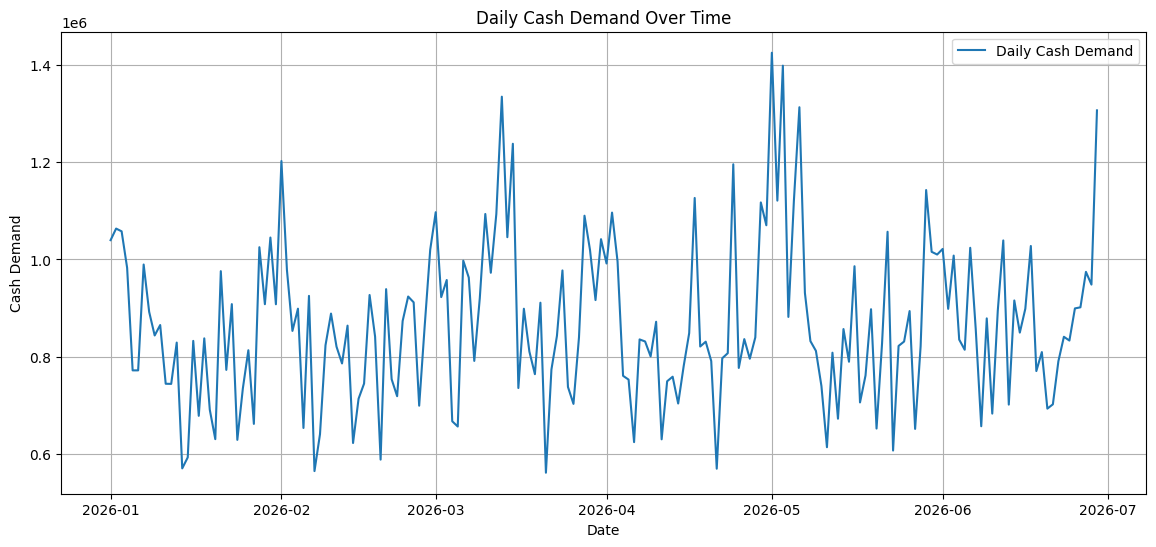

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Cash_Demand"],
    label="Daily Cash Demand"
)

plt.xlabel("Date")
plt.ylabel("Cash Demand")
plt.title("Daily Cash Demand Over Time")

plt.legend()
plt.grid(True)
plt.show()

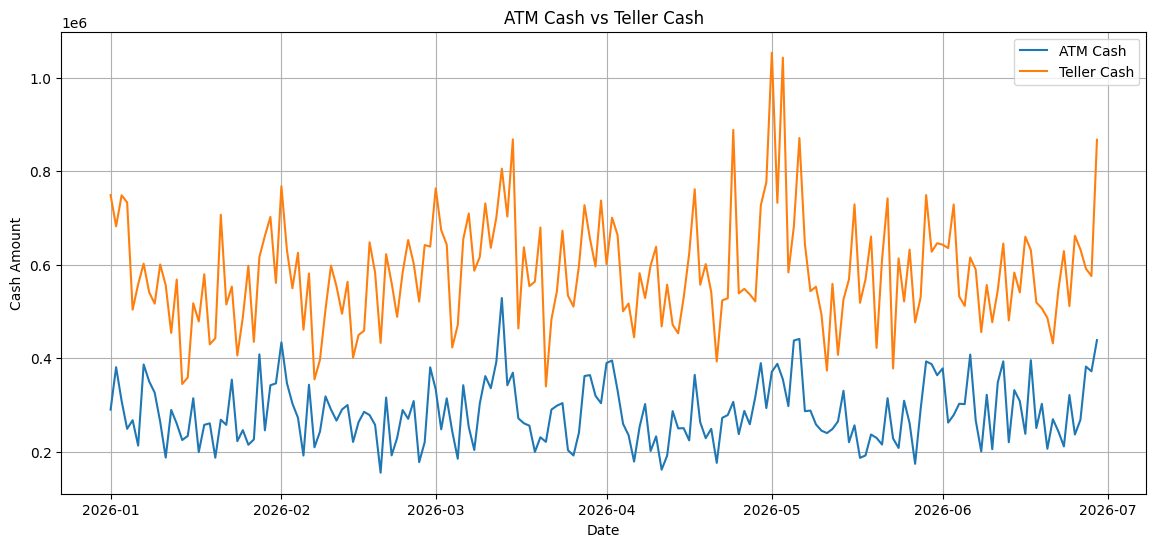

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["ATM_Cash"],
    label="ATM Cash"
)

plt.plot(
    df["Date"],
    df["Teller_Cash"],
    label="Teller Cash"
)

plt.xlabel("Date")
plt.ylabel("Cash Amount")
plt.title("ATM Cash vs Teller Cash")

plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Calculate the 7-day moving average
df["Moving_Average_7"] = df["Cash_Demand"].rolling(window=7).mean()

# Display the result
df[["Date", "Cash_Demand", "Moving_Average_7"]].tail(15)

,Date,Cash_Demand,Moving_Average_7
165,2026-06-15,849534.0,851708.857143
166,2026-06-16,898647.0,854546.142857
167,2026-06-17,1027615.0,903771.428571
168,2026-06-18,770553.0,886071.857143
169,2026-06-19,809552.0,853289.142857
170,2026-06-20,693258.0,852109.142857
171,2026-06-21,702103.0,821608.857143
172,2026-06-22,790748.0,813210.857143
173,2026-06-23,840938.0,804966.714286
174,2026-06-24,833203.0,777193.571429


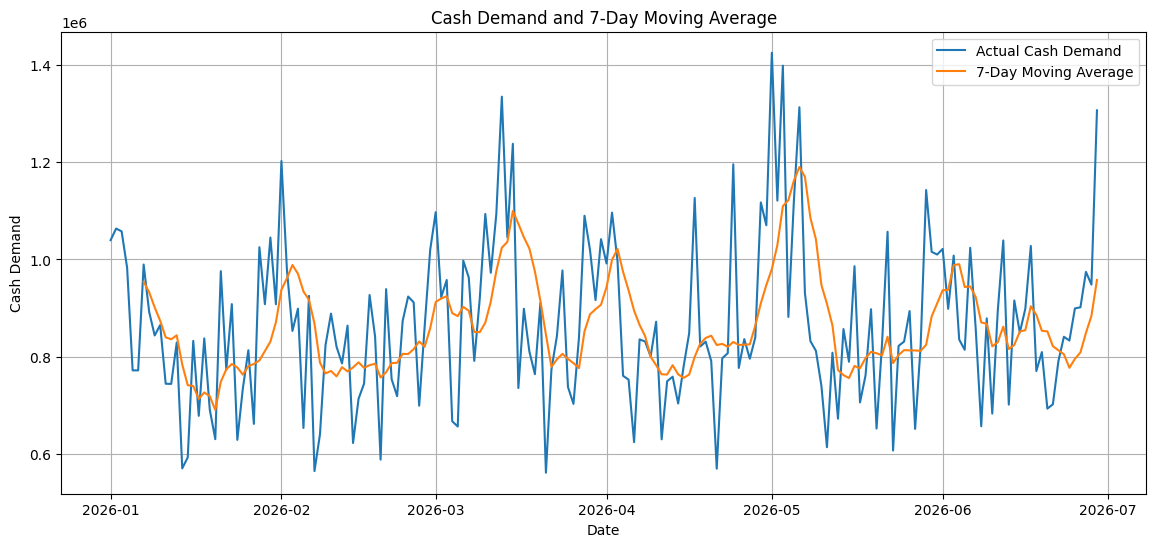

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Cash_Demand"],
    label="Actual Cash Demand"
)

plt.plot(
    df["Date"],
    df["Moving_Average_7"],
    label="7-Day Moving Average"
)

plt.xlabel("Date")
plt.ylabel("Cash Demand")
plt.title("Cash Demand and 7-Day Moving Average")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Convert boolean values into numerical values
df["Salary_Day_Flag"] = df["Salary_Day"].astype(int)
df["Festival_Week_Flag"] = df["Festival_Week"].astype(int)

# Check the new features
df[[
    "Date",
    "Cash_Demand",
    "Salary_Day_Flag",
    "Festival_Week_Flag"
]].head(15)

,Date,Cash_Demand,Salary_Day_Flag,Festival_Week_Flag
0,2026-01-01,1039606.0,1,0
1,2026-01-02,1063408.0,1,0
2,2026-01-03,1057723.0,1,0
3,2026-01-04,982764.0,0,0
4,2026-01-05,771902.0,0,0
5,2026-01-06,771904.0,0,0
6,2026-01-07,989506.0,0,0
7,2026-01-08,892092.0,0,0
8,2026-01-09,843663.0,0,0
9,2026-01-10,865107.0,0,0


In [15]:
salary_average = df.groupby("Salary_Day_Flag")["Cash_Demand"].mean()

print("Average cash demand:")
print(salary_average)

Average cash demand:
Salary_Day_Flag
0    8.245128e+05
1    1.038108e+06
Name: Cash_Demand, dtype: float64


In [16]:
print("Average demand on normal days:",
      round(salary_average[0], 2))

print("Average demand on salary days:",
      round(salary_average[1], 2))

Average demand on normal days: 824512.85
Average demand on salary days: 1038108.33


In [17]:
festival_average = df.groupby("Festival_Week_Flag")["Cash_Demand"].mean()

print("Average demand during normal weeks:",
      round(festival_average[0], 2))

print("Average demand during festival weeks:",
      round(festival_average[1], 2))

Average demand during normal weeks: 845773.63
Average demand during festival weeks: 1121666.21


In [21]:
# Day of week
# Salary Day
# Festival Week
# ATM Cash
# Teller Cash
# Deposits
# Moving Average

In [22]:
# Create useful features from the date

df["Day_of_Week"] = df["Date"].dt.dayofweek
df["Day_of_Month"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month

# Select the input features
features = [
    "Day_of_Week",
    "Day_of_Month",
    "Month",
    "Salary_Day_Flag",
    "Festival_Week_Flag",
    "ATM_Cash",
    "Teller_Cash",
    "Deposits",
    "Moving_Average_7"
]

# Remove rows containing NaN values
ml_data = df.dropna(subset=features + ["Cash_Demand"]).copy()

X = ml_data[features]
y = ml_data["Cash_Demand"]

print("Number of samples:", len(X))
print("Number of features:", len(features))

Number of samples: 174
Number of features: 9


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 139
Testing samples: 35


In [24]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [25]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Cash_Demand": y_test.values,
    "Predicted_Cash_Demand": y_pred.round(0)
})

results.head(10)

,Actual_Cash_Demand,Predicted_Cash_Demand
0,894450.0,877630.0
1,1010059.0,1014715.0
2,820949.0,824944.0
3,856831.0,854918.0
4,651566.0,680677.0
5,831186.0,832935.0
6,841234.0,850786.0
7,772907.0,789629.0
8,672524.0,682285.0
9,1334564.0,1219189.0


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

print("Model Performance")
print("------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Performance
------------------
MAE : 16507.24
RMSE: 27840.61


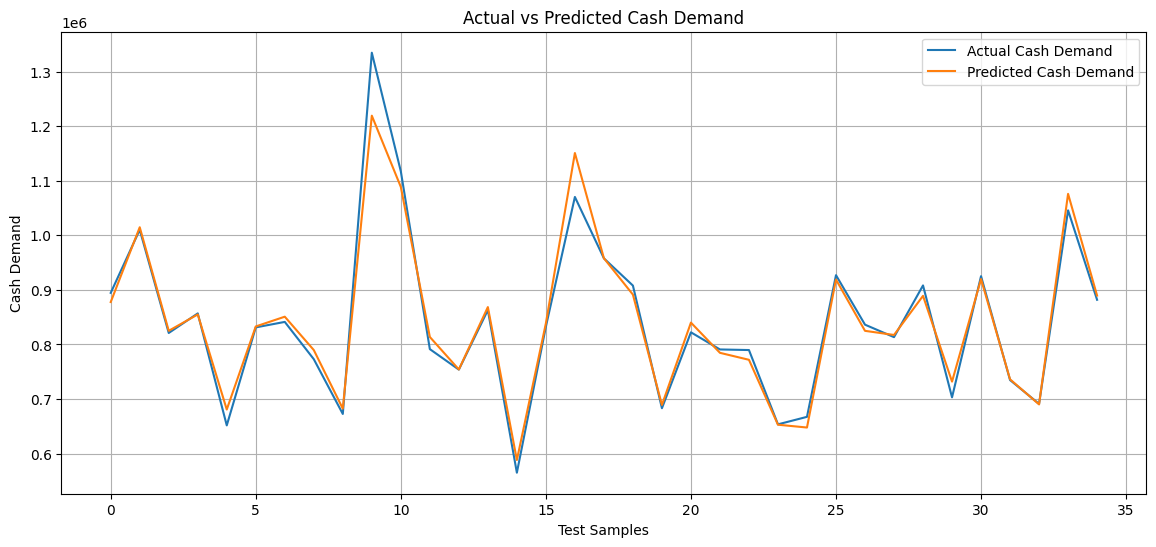

In [27]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.values,
    label="Actual Cash Demand"
)

plt.plot(
    y_pred,
    label="Predicted Cash Demand"
)

plt.xlabel("Test Samples")
plt.ylabel("Cash Demand")
plt.title("Actual vs Predicted Cash Demand")

plt.legend()
plt.grid(True)
plt.show()

In [28]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

              Feature  Importance
6         Teller_Cash    0.814329
5            ATM_Cash    0.165502
8    Moving_Average_7    0.007071
7            Deposits    0.005053
2               Month    0.002875
1        Day_of_Month    0.002657
0         Day_of_Week    0.001678
4  Festival_Week_Flag    0.000507
3     Salary_Day_Flag    0.000327


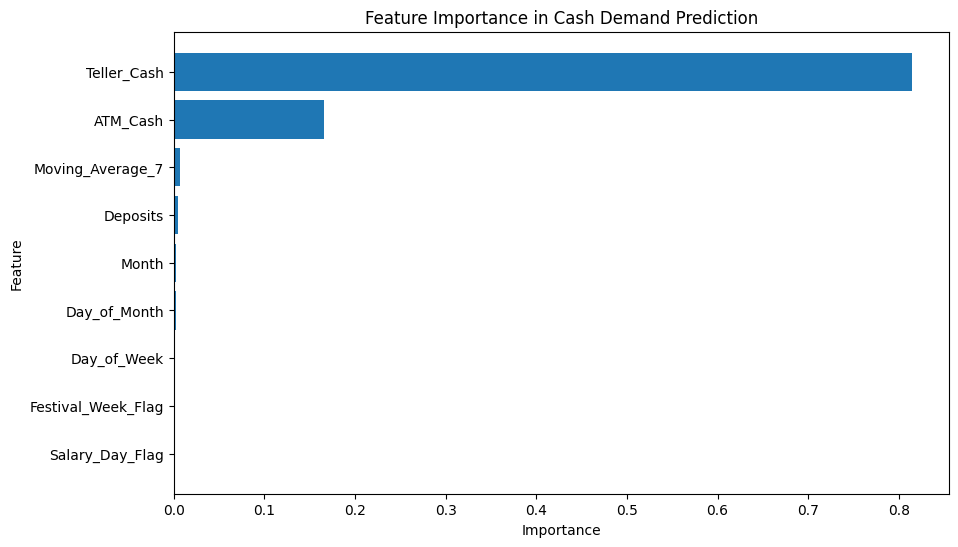

In [29]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in Cash Demand Prediction")

plt.gca().invert_yaxis()

plt.show()

In [30]:
# Calculate the average predicted cash demand
average_predicted_demand = np.mean(y_pred)

# Safety reserve = 10%
safety_reserve = average_predicted_demand * 0.10

# Recommended cash
recommended_cash = average_predicted_demand + safety_reserve

print("CASH FORECASTING RECOMMENDATION")
print("--------------------------------")
print("Average predicted demand:",
      round(average_predicted_demand, 2))

print("Safety reserve (10%):",
      round(safety_reserve, 2))

print("Recommended cash from Currency Chest:",
      round(recommended_cash, 2))

CASH FORECASTING RECOMMENDATION
--------------------------------
Average predicted demand: 841653.35
Safety reserve (10%): 84165.34
Recommended cash from Currency Chest: 925818.69


In [31]:
# Final Project Summary

print("=" * 55)
print("       BANK BRANCH CASH FORECASTING TOOL")
print("=" * 55)

print(f"Historical records       : {len(df)} days")
print(f"Average cash demand      : ₹{df['Cash_Demand'].mean():,.2f}")
print(f"Average ATM cash         : ₹{df['ATM_Cash'].mean():,.2f}")
print(f"Average Teller cash      : ₹{df['Teller_Cash'].mean():,.2f}")
print(f"Average deposits         : ₹{df['Deposits'].mean():,.2f}")

print("\nMODEL PERFORMANCE")
print("-" * 55)
print(f"MAE                      : ₹{mae:,.2f}")
print(f"RMSE                     : ₹{rmse:,.2f}")

print("\nCASH RECOMMENDATION")
print("-" * 55)
print(f"Predicted demand         : ₹{average_predicted_demand:,.2f}")
print(f"Safety reserve (10%)     : ₹{safety_reserve:,.2f}")
print(f"Recommended cash         : ₹{recommended_cash:,.2f}")

print("=" * 55)

       BANK BRANCH CASH FORECASTING TOOL
Historical records       : 180 days
Average cash demand      : ₹867,231.94
Average ATM cash         : ₹283,426.37
Average Teller cash      : ₹583,805.66
Average deposits         : ₹600,954.93

MODEL PERFORMANCE
-------------------------------------------------------
MAE                      : ₹16,507.24
RMSE                     : ₹27,840.61

CASH RECOMMENDATION
-------------------------------------------------------
Predicted demand         : ₹841,653.35
Safety reserve (10%)     : ₹84,165.34
Recommended cash         : ₹925,818.69


In [32]:
df.to_csv(
    "bank_cash_forecasting_dataset.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [33]:
results.to_csv(
    "cash_forecasting_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!
